# Partie A : Data management et nettoyage (Lyon)

Données : Inside Airbnb, Lyon, snapshot du 17/09/2026 (licence CC BY 4.0). Le prof a ajouté des erreurs volontaires dans les fichiers.

Responsable : membre 1

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Chemins : seule cellule à modifier
VILLE = "lyon"
DOSSIER = "../data/" + VILLE          # Colab : "/content/drive/MyDrive/data/" + VILLE
SORTIE = "../data_clean"
SEED = 42

print("pandas", pd.__version__)       # la signature change selon la version de pandas

pandas 2.2.3


Fonction signature de l'annexe A (copiée sans modification) :

In [2]:
import hashlib
import pandas as pd


def signature(df, nom):
     """Résumé détaillé et empreinte d'une table nettoyée."""
     copie = df.copy()
     for col in copie.columns:
          # les listes (ex. amenities) sont converties en texte pour pouvoir être résumées
          if copie[col].map(lambda v: isinstance(v, (list, dict, set, tuple))).any():
              copie[col] = copie[col].map(str)
     empreinte = hashlib.md5(
          pd.util.hash_pandas_object(copie.astype(str), index=False).values.tobytes()
     ).hexdigest()


     print(f"=== Signature : {nom} ===")
     print(f"Lignes : {copie.shape[0]}          Colonnes : {copie.shape[1]}")
     print(f"Empreinte MD5 : {empreinte}")
     resume = pd.DataFrame({
          "type": copie.dtypes.astype(str),
          "manquants": copie.isna().sum(),
          "pct_manquants": (copie.isna().mean() * 100).round(2),
          "valeurs_distinctes": copie.nunique(),
     })
     display(resume)
     numeriques = copie.select_dtypes("number")
     if not numeriques.empty:
          display(numeriques.describe().T.round(2))
     return empreinte

In [3]:
listings_brut = pd.read_csv(DOSSIER + "/listings.csv.gz", low_memory=False)
reviews_brut = pd.read_csv(DOSSIER + "/reviews.csv.gz")
quartiers = pd.read_csv(DOSSIER + "/neighbourhoods.csv")

print("listings :", listings_brut.shape)
print("reviews :", reviews_brut.shape)
print("quartiers :", quartiers.shape)

listings : (9321, 90)
reviews : (478054, 6)
quartiers : (9, 2)


## A1 : Cadrage

### Les questions et les indicateurs

| Question | Indicateur | Colonnes |
|---|---|---|
| Q1 Taille du marché, saisonnalité | Nombre d'annonces actives (au moins 1 avis sur 12 mois et des jours disponibles) ; nombre d'avis par mois | `number_of_reviews_ltm`, `availability_365`, reviews `date` |
| Q2 Particuliers ou professionnels | Part des annonces d'hôtes qui ont 2 annonces ou plus ; part détenue par les 10 % d'hôtes les plus gros | `host_id`, `calculated_host_listings_count` |
| Q3 Meilleurs quartiers | Revenu médian, occupation médiane, annonces pour 1 000 habitants par arrondissement | `neighbourhood_cleansed`, `estimated_revenue_l365d`, `estimated_occupancy_l365d` |
| Q4 Droit de louer | Part des annonces avec un numéro d'enregistrement, en bail mobilité, sans numéro ; part des annonces avec 30 nuits minimum ou plus | `license`, `minimum_nights` |
| Q5 Le produit qui rapporte | Prix et revenu médians selon le type de logement, la capacité et les équipements | `room_type`, `accommodates`, `bedrooms`, `amenities`, `price` |
| Q6 (bonus) Ce que veulent les voyageurs | Mots les plus fréquents dans les avis, avis positifs ou négatifs | reviews `comments`, `review_scores_rating` |

On utilise des médianes plutôt que des moyennes, car les prix et les revenus ont quelques valeurs très élevées.

### La réglementation à Lyon

| | Règle | Sources |
|---|---|---|
| 1. Enregistrement | Obligatoire pour tout meublé de tourisme. Déclaration en ligne à la Ville de Lyon, le numéro (13 caractères) doit être affiché sur l'annonce. | [lyon.fr](https://www.lyon.fr/node/838135), [entreprises.gouv.fr](https://www.entreprises.gouv.fr/fr/mot-cle/location-touristique) |
| 2. Résidence principale | Location possible 90 nuits par an maximum depuis le 1er janvier 2026 (avant : 120). | [lyon.fr](https://www.lyon.fr/node/838135), [Lyon Capitale](https://www.lyoncapitale.fr/actualite/la-ville-de-lyon-adopte-trois-mesures-pour-faire-face-a-la-crise-du-logement) |
| 3. Résidence secondaire, investissement | Il faut une autorisation de changement d'usage. Dans l'hypercentre et pour les logements de 35 m² ou plus, il faut une compensation : transformer un autre local en logement, dans le même arrondissement. | [lyon.fr](https://www.lyon.fr/node/838135) |
| 4. Durée minimale | La loi ne donne pas de nombre de nuits ("courtes durées", "clientèle de passage"). On prend moins de 30 nuits, car le bail mobilité dure de 1 à 10 mois. | [service-public.fr](https://www.service-public.gouv.fr/particuliers/vosdroits/F34759), [CMS](https://cms.law/en/fra/news-information/location-de-meubles-touristiques-de-courte-duree-et-changement-d-usage) |
| 5. Sanctions | Changement d'usage sans autorisation : jusqu'à 100 000 € d'amende. Pas de déclaration : jusqu'à 10 000 €. Les règles se durcissent (loi Le Meur 2024 : 90 nuits, enregistrement national, DPE). | [notaires.fr](https://www.notaires.fr/fr/article/location-les-regles-applicables-aux-meubles-de-tourisme), [AGN Avocats](https://www.agn-avocats.fr/blog/immobilier/loi-le-meur-et-meubles-de-tourisme-enregistrement-mai-2026/) |

Pour un investisseur, le point bloquant est la ligne 3 : un logement acheté pour la location courte durée demande presque toujours une compensation.

### Données personnelles

- On supprime : le prénom, la présentation et la photo de l'hôte (`host_name`, `host_about`, `host_picture_url`, `host_url`...), le nom et la description de l'annonce, et le prénom et l'identifiant des voyageurs (`reviewer_name`, `reviewer_id`).
- On garde `host_id` pour compter les annonces par hôte (Q2), sans jamais l'afficher.
- On garde le texte des avis (`comments`) pour la partie D, mais on n'affiche jamais un avis entier, car il contient souvent des prénoms.

## A2 : Exploration et dictionnaire

In [4]:
listings_brut.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9321 entries, 0 to 9320
Data columns (total 90 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            9321 non-null   int64  
 1   listing_url                                   9321 non-null   object 
 2   scrape_id                                     9321 non-null   int64  
 3   last_scraped                                  9321 non-null   object 
 4   source                                        4176 non-null   object 
 5   name                                          9321 non-null   object 
 6   description                                   9268 non-null   object 
 7   neighborhood_overview                         0 non-null      float64
 8   picture_url                                   9321 non-null   object 
 9   host_id                                       9321 non-null   i

In [5]:
# Pourcentage de valeurs manquantes par colonne
manquants = (listings_brut.isna().mean() * 100).round(1)
print(manquants.sort_values(ascending=False).head(20))

neighborhood_overview           100.0
host_since                      100.0
host_response_time              100.0
host_thumbnail_url              100.0
host_acceptance_rate            100.0
host_response_rate              100.0
host_verifications              100.0
neighbourhood                   100.0
host_total_listings_count       100.0
host_neighbourhood              100.0
calendar_updated                100.0
instant_bookable                100.0
neighbourhood_group_cleansed    100.0
bathrooms                       100.0
host_about                       56.3
source                           55.2
estimated_revenue_l365d          44.7
price_quote_price_per_night      44.7
price_quote_total_price          44.7
price                            44.7
dtype: float64


In [6]:
vides = manquants[manquants == 100]
print(len(vides), "colonnes complètement vides :")
print(list(vides.index))

14 colonnes complètement vides :
['neighborhood_overview', 'host_since', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_thumbnail_url', 'host_neighbourhood', 'host_total_listings_count', 'host_verifications', 'neighbourhood', 'neighbourhood_group_cleansed', 'bathrooms', 'calendar_updated', 'instant_bookable']


In [7]:
reviews_brut.info()
print("id d'avis en double :", reviews_brut["id"].duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 478054 entries, 0 to 478053
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   listing_id     478054 non-null  int64 
 1   id             478054 non-null  int64 
 2   date           478054 non-null  object
 3   reviewer_id    478054 non-null  int64 
 4   reviewer_name  478054 non-null  object
 5   comments       477213 non-null  object
dtypes: int64(3), object(3)
memory usage: 21.9+ MB
id d'avis en double : 6968


Remarques : 14 colonnes sont vides à Lyon (dont `bathrooms`, `host_response_rate`, `host_acceptance_rate`, `instant_bookable`). On les laisse de côté. Le nombre de salles de bain viendra de `bathrooms_text`. Dans les avis, des `id` sont en double : on les traite en A5.

### Dictionnaire des 26 colonnes retenues

| Colonne | Signification | Type cible | Unité | Décision |
|---|---|---|---|---|
| id | identifiant de l'annonce | entier | - | garder |
| host_id | identifiant de l'hôte | entier | - | garder (jamais affiché) |
| calculated_host_listings_count | nombre d'annonces de l'hôte à Lyon | entier | annonces | garder |
| host_is_superhost | hôte Superhôte ou non | booléen | - | transformer |
| neighbourhood_cleansed | arrondissement | texte | - | transformer |
| latitude | latitude | décimal | degrés | transformer |
| longitude | longitude | décimal | degrés | transformer |
| property_type | type de bien | texte | - | garder |
| room_type | logement entier, chambre... | texte | - | transformer |
| accommodates | capacité | entier | personnes | garder |
| bedrooms | chambres | décimal | chambres | garder |
| beds | lits | décimal | lits | garder |
| bathrooms_text | salles de bain (texte) | texte | - | transformer en nb_sdb |
| amenities | équipements | liste | - | transformer |
| price | prix par nuit | décimal | € | transformer |
| price_quote_price_per_night | prix d'un devis réel | décimal | € | écarter après A5 (sert de contrôle) |
| minimum_nights | durée minimale | décimal | nuits | garder |
| availability_365 | jours disponibles sur un an | entier | jours | garder |
| number_of_reviews | nombre d'avis | entier | avis | garder |
| number_of_reviews_ltm | avis des 12 derniers mois | entier | avis | garder |
| first_review | date du premier avis | date | - | transformer |
| last_review | date du dernier avis | date | - | transformer |
| review_scores_rating | note globale | décimal | sur 5 | garder |
| estimated_occupancy_l365d | nuits réservées estimées sur un an | entier | nuits | garder |
| estimated_revenue_l365d | revenu estimé sur un an | décimal | € | garder |
| license | numéro d'enregistrement | texte | - | garder |

Les trois dernières colonnes de prix, d'occupation et de revenu ne sont pas dans le dictionnaire officiel : leur sens vient de leur nom et de la page "Hypothèses de données" d'Inside Airbnb.

In [8]:
colonnes = ["id", "host_id", "calculated_host_listings_count", "host_is_superhost",
            "neighbourhood_cleansed", "latitude", "longitude", "property_type", "room_type",
            "accommodates", "bedrooms", "beds", "bathrooms_text", "amenities", "price",
            "price_quote_price_per_night", "minimum_nights", "availability_365",
            "number_of_reviews", "number_of_reviews_ltm", "first_review", "last_review",
            "review_scores_rating", "estimated_occupancy_l365d", "estimated_revenue_l365d", "license"]

# Type d'origine et % de manquants des colonnes retenues
dictionnaire = pd.DataFrame({"type_origine": listings_brut[colonnes].dtypes,
                             "pct_manquants": manquants[colonnes]})
dictionnaire

,type_origine,pct_manquants
id,int64,0.0
host_id,int64,0.0
calculated_host_listings_count,int64,0.0
host_is_superhost,object,0.0
neighbourhood_cleansed,object,0.0
latitude,float64,0.0
longitude,float64,0.0
property_type,object,0.0
room_type,object,0.0
accommodates,int64,0.0


## A3 : Sélection et typage

In [9]:
listings = listings_brut[colonnes].copy()
reviews = reviews_brut[["id", "listing_id", "date", "comments"]].copy()
print(listings.shape, reviews.shape)

(9321, 26) (478054, 4)


### Le prix

In [10]:
# Les différentes écritures du prix (exemples)
print(listings["price"].dropna().sample(15, random_state=SEED).tolist())

['$233.33', '$70.00', '$110.75', '$85.67', '$122.00', '$177.00', '$89.00', '$22.67', '$227.50', '$73.75', '$0.00', '$117.00', '$149.00', '$129.00', '$85.50']


In [11]:
def convertir_prix(texte):
    if pd.isna(texte):
        return np.nan
    texte = texte.replace("$", "").replace("CAD", "").replace("dollars", "").replace(" ", "")
    if "," in texte and "." not in texte:
        texte = texte.replace(",", ".")     # 180,00 -> 180.00
    else:
        texte = texte.replace(",", "")      # 2,388.45 -> 2388.45
    return float(texte)

listings["price"] = listings["price"].map(convertir_prix)
illisibles = listings_brut["price"].notna().sum() - listings["price"].notna().sum()
print("prix illisibles :", illisibles)

prix illisibles : 0


La devise est l'euro : le $ vient de l'export d'Inside Airbnb (voir dictionnaire officiel) et les devis réels sont en EUR. Les prix écrits "CAD" ou "dollars" sont égaux au devis, ce sont juste des écritures différentes.

Les taux d'hôte (`host_response_rate`, `host_acceptance_rate`) sont vides à 100 % à Lyon : rien à convertir.

### Les booléens

In [12]:
print(listings["host_is_superhost"].value_counts())

host_is_superhost
f        7276
t        1952
Faux       26
no         19
0          17
FALSE      16
yes         6
Vrai        5
1           3
TRUE        1
Name: count, dtype: int64


In [13]:
vrai_faux = {"t": True, "TRUE": True, "Vrai": True, "yes": True, "1": True,
             "f": False, "FALSE": False, "Faux": False, "no": False, "0": False}
listings["host_is_superhost"] = listings["host_is_superhost"].map(vrai_faux)
print("illisibles :", listings["host_is_superhost"].isna().sum())

illisibles : 0


### Les dates

In [14]:
# Deux formats : 2024-06-30 et 30/06/2024
def convertir_date(colonne):
    date1 = pd.to_datetime(colonne, format="%Y-%m-%d", errors="coerce")
    date2 = pd.to_datetime(colonne, format="%d/%m/%Y", errors="coerce")
    return date1.fillna(date2)

listings["first_review"] = convertir_date(listings["first_review"])
listings["last_review"] = convertir_date(listings["last_review"])
reviews["date"] = convertir_date(reviews["date"])

print("illisibles first_review :", listings_brut["first_review"].notna().sum() - listings["first_review"].notna().sum())
print("illisibles last_review :", listings_brut["last_review"].notna().sum() - listings["last_review"].notna().sum())
print("illisibles date des avis :", reviews_brut["date"].notna().sum() - reviews["date"].notna().sum())

illisibles first_review : 0
illisibles last_review : 0
illisibles date des avis : 0


### Salles de bain et équipements

In [15]:
def nombre_sdb(texte):
    if pd.isna(texte):
        return np.nan
    if "half" in texte.lower():
        return 0.5                           # "Half-bath" = demi salle de bain
    return float(texte.split(" ")[0])        # "1.5 baths" -> 1.5

listings["nb_sdb"] = listings["bathrooms_text"].map(nombre_sdb)
listings = listings.drop(columns="bathrooms_text")

# amenities est un texte qui ressemble à une liste : json.loads le transforme en vraie liste
listings["amenities"] = listings["amenities"].map(json.loads)
listings["nb_equipements"] = listings["amenities"].map(len)
print(listings[["nb_sdb", "nb_equipements"]].describe())

            nb_sdb  nb_equipements
count  9313.000000     9321.000000
mean      1.105390       25.607338
std       0.395463       13.963252
min       0.000000        0.000000
25%       1.000000       13.000000
50%       1.000000       26.000000
75%       1.000000       36.000000
max      12.000000       79.000000


### Type de logement et quartier

In [16]:
print(listings["room_type"].value_counts())

room_type
Entire home/apt    7347
Private room       1822
Entire home          34
Shared room          31
Hotel room           27
entire home/apt      26
ENTIRE HOME/APT      19
PRIVATE ROOM          8
Private               6
private room          1
Name: count, dtype: int64


In [17]:
types = {"entire home/apt": "Entire home/apt", "entire home": "Entire home/apt",
         "private room": "Private room", "private": "Private room",
         "shared room": "Shared room", "hotel room": "Hotel room"}
listings["room_type"] = listings["room_type"].str.strip().str.lower().map(types)
print(listings["room_type"].value_counts(dropna=False))

room_type
Entire home/apt    7426
Private room       1837
Shared room          31
Hotel room           27
Name: count, dtype: int64


In [18]:
print(listings["neighbourhood_cleansed"].nunique(), "écritures pour", len(quartiers), "arrondissements")

# On enlève les espaces et les majuscules, puis on remet le nom officiel
noms_officiels = {}
for nom in quartiers["neighbourhood"]:
    noms_officiels[nom.lower()] = nom
listings["neighbourhood_cleansed"] = listings["neighbourhood_cleansed"].str.strip().str.lower().map(noms_officiels)
print(listings["neighbourhood_cleansed"].value_counts(dropna=False))

36 écritures pour 9 arrondissements
neighbourhood_cleansed
3e Arrondissement     1625
7e Arrondissement     1396
1er Arrondissement    1374
2e Arrondissement     1195
5e Arrondissement      904
6e Arrondissement      828
8e Arrondissement      715
4e Arrondissement      700
9e Arrondissement      584
Name: count, dtype: int64


## A4 : Valeurs manquantes

In [19]:
print((listings.isna().mean() * 100).round(1).sort_values(ascending=False).head(12))

estimated_revenue_l365d        44.7
price                          44.7
price_quote_price_per_night    44.7
license                        37.2
review_scores_rating           18.1
first_review                   18.1
last_review                    18.1
beds                            1.5
minimum_nights                  0.7
nb_sdb                          0.1
id                              0.0
bedrooms                        0.0
dtype: float64

In [20]:
# Pourquoi le prix manque-t-il ? On regarde si l'annonce est réservable
pd.crosstab(listings["price"].isna(), listings["availability_365"] == 0,
            rownames=["prix manquant"], colnames=["0 jour disponible"])

0 jour disponible,False,True
prix manquant,,
False,5089,66
True,546,3620


In [21]:
# Pourquoi la note manque-t-elle ? On regarde si l'annonce a des avis
pd.crosstab(listings["review_scores_rating"].isna(), listings["number_of_reviews"] == 0,
            rownames=["note manquante"], colnames=["0 avis"])

0 avis,False,True
note manquante,,
False,7630,0
True,0,1691


| Colonne | % manquant | Stratégie | Pourquoi |
|---|---|---|---|
| price, estimated_revenue_l365d | 45 % | on laisse vide + colonne `prix_manquant` | la plupart des annonces sans prix ne sont pas réservables (0 jour disponible) : inventer un prix inventerait un revenu |
| first_review, last_review, review_scores_rating | 18 % | on laisse vide | ces annonces n'ont aucun avis, il n'y a donc pas de note |
| license | 37 % | catégorie "Non renseigné" | l'absence de numéro est une information pour Q4 |
| beds, bedrooms | 1,5 % et moins | médiane par capacité | le nombre de lits dépend de la capacité |
| nb_sdb | 0,1 % | médiane | très peu de lignes |
| minimum_nights | 0,7 % | mode (valeur la plus fréquente) | très peu de lignes |
| comments (avis) | 0,3 % | on garde l'avis sans texte | il compte quand même pour la saisonnalité (Q1) |

In [22]:
listings["prix_manquant"] = listings["price"].isna()
listings["license"] = listings["license"].fillna("Non renseigné")

listings["beds"] = listings["beds"].fillna(listings.groupby("accommodates")["beds"].transform("median"))
listings["bedrooms"] = listings["bedrooms"].fillna(listings.groupby("accommodates")["bedrooms"].transform("median"))
listings["nb_sdb"] = listings["nb_sdb"].fillna(listings["nb_sdb"].median())
listings["minimum_nights"] = listings["minimum_nights"].fillna(listings["minimum_nights"].mode()[0])

print(listings.isna().sum()[listings.isna().sum() > 0])

price                          4166
price_quote_price_per_night    4166
first_review                   1691
last_review                    1691
review_scores_rating           1691
estimated_revenue_l365d        4166
dtype: int64


## A5 : Doublons, incohérences et valeurs aberrantes

### Doublons dans listings

In [23]:
# Doublons exacts (on ne compare pas amenities, qui contient des listes)
sans_liste = listings.columns.drop("amenities")
doublons_exacts = listings.duplicated(subset=sans_liste)
print("doublons exacts :", doublons_exacts.sum())

rejets_listings = listings[doublons_exacts].copy()
rejets_listings["motif"] = "doublon exact"
listings = listings[~doublons_exacts].copy()

doublons exacts : 94


In [24]:
# Doublons partiels : même id, mais des valeurs différentes
meme_id = listings["id"].duplicated(keep=False)
print("lignes avec un id en double :", meme_id.sum())
listings[meme_id].sort_values("id")[["id", "price", "price_quote_price_per_night"]].head(6)

lignes avec un id en double : 52


,id,price,price_quote_price_per_night
7406,2590016,49.16,49.16
5314,2590016,54.08,49.16
3598,7082561,133.10,121.00
7411,7082561,121.00,121.00
8458,15527405,184.50,184.50
2139,15527405,202.95,184.50


Seul le prix change. Une version est égale au prix du devis réel, l'autre est 10 % plus chère. On garde la version égale au devis.

In [25]:
a_ecarter = meme_id & (listings["price"] != listings["price_quote_price_per_night"])
print("doublons partiels écartés :", a_ecarter.sum())

rejet = listings[a_ecarter].copy()
rejet["motif"] = "doublon partiel"
rejets_listings = pd.concat([rejets_listings, rejet])
listings = listings[~a_ecarter].copy()
print("id uniques :", listings["id"].is_unique)

doublons partiels écartés : 26
id uniques : True


### Doublons dans reviews

In [26]:
doublons_exacts = reviews.duplicated()
print("doublons exacts :", doublons_exacts.sum())
rejets_reviews = reviews[doublons_exacts].copy()
rejets_reviews["motif"] = "doublon exact"
reviews = reviews[~doublons_exacts].copy()

# Doublons partiels : le même avis (même id) rattaché à plusieurs annonces. On garde la première ligne.
doublons_partiels = reviews["id"].duplicated()
print("doublons partiels :", doublons_partiels.sum())
rejet = reviews[doublons_partiels].copy()
rejet["motif"] = "doublon partiel"
rejets_reviews = pd.concat([rejets_reviews, rejet])
reviews = reviews[~doublons_partiels].copy()

doublons exacts : 4733
doublons partiels : 2235


### Valeurs impossibles dans listings

In [27]:
# Coordonnées : Lyon est entre 45.70 et 45.82 de latitude, 4.76 et 4.91 de longitude
inversees = listings["latitude"].between(4.76, 4.91) & listings["longitude"].between(45.70, 45.82)
zero = (listings["latitude"] == 0) & (listings["longitude"] == 0)
print("coordonnées inversées :", inversees.sum(), "| coordonnées à 0 :", zero.sum())

# Inversées : on échange les deux colonnes. A zéro : position inconnue, on met vide
ancienne_latitude = listings.loc[inversees, "latitude"]
listings.loc[inversees, "latitude"] = listings.loc[inversees, "longitude"]
listings.loc[inversees, "longitude"] = ancienne_latitude
listings.loc[zero, ["latitude", "longitude"]] = np.nan

coordonnées inversées : 28 | coordonnées à 0 : 9


In [28]:
# Capacité : 0 ou 99 personnes est impossible (maximum Airbnb : 16)
print(listings["accommodates"].value_counts().sort_index())
capacite_impossible = (listings["accommodates"] == 0) | (listings["accommodates"] > 16)
print("capacités impossibles :", capacite_impossible.sum())

rejet = listings[capacite_impossible].copy()
rejet["motif"] = "capacité impossible"
rejets_listings = pd.concat([rejets_listings, rejet])
listings = listings[~capacite_impossible].copy()

accommodates
0       13
1      493
2     4220
3      563
4     2585
5      321
6      657
7       80
8      152
9       12
10      40
11      10
12      13
13       4
14       8
15       2
16      13
99      15
Name: count, dtype: int64
capacités impossibles : 28


In [29]:
# Durée minimale négative : c'est une erreur de signe, on prend la valeur positive
negatives = listings["minimum_nights"] < 0
print("durées minimales négatives :", negatives.sum())
listings.loc[negatives, "minimum_nights"] = listings.loc[negatives, "minimum_nights"].abs()

durées minimales négatives : 18


In [30]:
# Prix impossibles : négatif, 0, ou 99999. On le remplace par le prix du devis réel de l'annonce
prix_impossible = (listings["price"] <= 0) | (listings["price"] == 99999)
print("prix impossibles :", prix_impossible.sum())
listings.loc[prix_impossible, "price"] = listings.loc[prix_impossible, "price_quote_price_per_night"]

prix impossibles : 55


In [31]:
# Note hors de l'échelle 1 à 5 (-1 ou 99) : la vraie note est inconnue, on met vide
note_impossible = listings["review_scores_rating"].notna() & ~listings["review_scores_rating"].between(1, 5)
print("notes impossibles :", note_impossible.sum())
listings.loc[note_impossible, "review_scores_rating"] = np.nan

notes impossibles : 28


In [32]:
# Dates : dernier avis après la collecte (19/09/2026) ou premier avis après le dernier
date_collecte = pd.to_datetime("2026-09-19")
dates_impossibles = (listings["last_review"] > date_collecte) | (listings["first_review"] > listings["last_review"])
print("dates impossibles :", dates_impossibles.sum())
listings.loc[dates_impossibles, ["first_review", "last_review"]] = pd.NaT

dates impossibles : 64


### Valeurs impossibles dans reviews

In [33]:
# Avis daté après la collecte
avis_futurs = reviews["date"] > date_collecte
# Avis d'une annonce qui n'existe pas (ou qui a été écartée)
avis_orphelins = ~reviews["listing_id"].isin(listings["id"])
print("avis futurs :", avis_futurs.sum(), "| avis orphelins :", avis_orphelins.sum())

rejet = reviews[avis_futurs].copy()
rejet["motif"] = "date après la collecte"
rejets_reviews = pd.concat([rejets_reviews, rejet])
reviews = reviews[~avis_futurs].copy()

avis_orphelins = ~reviews["listing_id"].isin(listings["id"])
rejet = reviews[avis_orphelins].copy()
rejet["motif"] = "annonce absente"
rejets_reviews = pd.concat([rejets_reviews, rejet])
reviews = reviews[~avis_orphelins].copy()

avis futurs : 469 | avis orphelins : 2764


### Valeurs aberrantes : prix et durée minimale

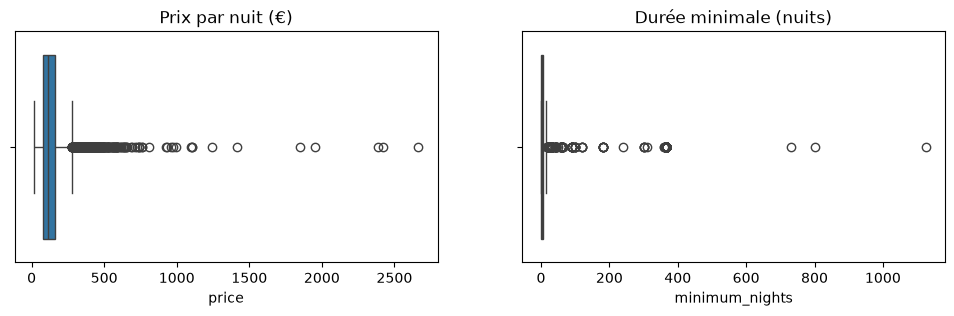

Q1 = 79.07499999999999 | Q3 = 158.0 | seuil = 394.77500000000003


In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
sns.boxplot(x=listings["price"], ax=axes[0])
axes[0].set_title("Prix par nuit (€)")
sns.boxplot(x=listings["minimum_nights"], ax=axes[1])
axes[1].set_title("Durée minimale (nuits)")
plt.show()

Q1 = listings["price"].quantile(0.25)
Q3 = listings["price"].quantile(0.75)
IQR = Q3 - Q1
seuil = Q3 + 3 * IQR
print("Q1 =", Q1, "| Q3 =", Q3, "| seuil =", seuil)

In [35]:
# Les prix les plus élevés : ce sont de grands logements
listings.sort_values("price", ascending=False)[["price", "accommodates", "bedrooms"]].head(8)

,price,accommodates,bedrooms
1071,2665.00,14,7.0
4436,2420.00,16,18.0
605,2388.45,4,2.0
5604,1952.00,16,12.0
5477,1850.00,16,1.0
8261,1415.00,2,0.0
6129,1243.00,16,5.0
7804,1106.20,4,1.0


Choix pour le prix : on garde les prix au-dessus du seuil, car ce sont de grands logements (10 à 16 personnes). On les signale avec la colonne `prix_extreme` pour pouvoir les exclure des moyennes en B et C.

Choix pour la durée minimale : 30 nuits (bail mobilité) et 365 nuits (annonce fermée à la courte durée) sont fréquentes et utiles pour Q4, on les garde. Au-delà de 365 nuits, on ramène à 365.

In [36]:
listings["prix_extreme"] = listings["price"] > seuil
print("prix extrêmes :", listings["prix_extreme"].sum())

trop_long = listings["minimum_nights"] > 365
print("durées supérieures à 365 :", trop_long.sum())
listings.loc[trop_long, "minimum_nights"] = 365

prix extrêmes : 155
durées supérieures à 365 : 3


### Tableau des anomalies et rejets

| Fichier | Anomalie | Colonnes | Traitement |
|---|---|---|---|
| listings | doublons exacts | toutes | écartés |
| listings | doublons partiels (prix +10 %) | id, price | on garde la version égale au devis |
| listings | coordonnées inversées / à 0 | latitude, longitude | échangées / mises à vide |
| listings | capacité 0 ou 99 | accommodates | écartées |
| listings | durée minimale négative | minimum_nights | signe corrigé |
| listings | prix négatif, 0 ou 99999 | price | remplacé par le devis réel |
| listings | note -1 ou 99 | review_scores_rating | mise à vide |
| listings | dates d'avis impossibles | first_review, last_review | mises à vide |
| listings | prix très élevés | price | gardés, signalés (prix_extreme) |
| listings | durée minimale > 365 | minimum_nights | ramenée à 365 |
| reviews | doublons exacts et partiels | id | écartés |
| reviews | avis en 2027 | date | écartés |
| reviews | avis d'une annonce absente | listing_id | écartés |

In [37]:
print("Annonces écartées :")
print(rejets_listings["motif"].value_counts())
print("\nAvis écartés :")
print(rejets_reviews["motif"].value_counts())

Annonces écartées :
motif
doublon exact          94
capacité impossible    28
doublon partiel        26
Name: count, dtype: int64

Avis écartés :
motif
doublon exact             4733
annonce absente           2763
doublon partiel           2235
date après la collecte     469
Name: count, dtype: int64


## A6 : Contrôles, bilan et signature

In [38]:
# La colonne du devis a servi de contrôle, on la retire
listings = listings.drop(columns="price_quote_price_per_night")

# On trie par id pour que la signature soit toujours la même
listings = listings.sort_values("id").reset_index(drop=True)
reviews = reviews.sort_values("id").reset_index(drop=True)

In [39]:
# Chaque contrôle compte les lignes en erreur : on attend 0 partout
print("1. id en double :", listings["id"].duplicated().sum())
print("2. prix <= 0 :", (listings["price"] <= 0).sum())
print("3. coordonnées hors de Lyon :", (listings["latitude"].notna() & ~listings["latitude"].between(45.70, 45.82)).sum())
print("4. premier avis après le dernier :", (listings["first_review"] > listings["last_review"]).sum())
print("5. dernier avis après la collecte :", (listings["last_review"] > date_collecte).sum())
print("6. quartier inconnu :", (~listings["neighbourhood_cleansed"].isin(quartiers["neighbourhood"])).sum())
print("7. availability_365 hors de 0 à 365 :", (~listings["availability_365"].between(0, 365)).sum())
print("8. capacité hors de 1 à 16 :", (~listings["accommodates"].between(1, 16)).sum())
print("9. durée minimale hors de 1 à 365 :", (~listings["minimum_nights"].between(1, 365)).sum())
print("10. note hors de 1 à 5 :", (listings["review_scores_rating"].notna() & ~listings["review_scores_rating"].between(1, 5)).sum())
print("11. type de logement manquant :", listings["room_type"].isna().sum())
print("12. avis en double :", reviews["id"].duplicated().sum())
print("13. avis après la collecte :", (reviews["date"] > date_collecte).sum())
print("14. avis sans annonce :", (~reviews["listing_id"].isin(listings["id"])).sum())

1. id en double : 0
2. prix <= 0 : 0
3. coordonnées hors de Lyon : 0
4. premier avis après le dernier : 0
5. dernier avis après la collecte : 0
6. quartier inconnu : 0
7. availability_365 hors de 0 à 365 : 0
8. capacité hors de 1 à 16 : 0
9. durée minimale hors de 1 à 365 : 0
10. note hors de 1 à 5 : 0
11. type de logement manquant : 0
12. avis en double : 0
13. avis après la collecte : 0
14. avis sans annonce : 0


In [40]:
bilan = pd.DataFrame({
    "listings avant": [listings_brut.shape[0], listings_brut.shape[1], round(listings_brut.isna().mean().mean() * 100, 1)],
    "listings après": [listings.shape[0], listings.shape[1], round(listings.isna().mean().mean() * 100, 1)],
    "reviews avant": [reviews_brut.shape[0], reviews_brut.shape[1], round(reviews_brut.isna().mean().mean() * 100, 1)],
    "reviews après": [reviews.shape[0], reviews.shape[1], round(reviews.isna().mean().mean() * 100, 1)],
}, index=["lignes", "colonnes", "% manquants"], dtype=object)
bilan

,listings avant,listings après,reviews avant,reviews après
lignes,9321,9173,478054,467854
colonnes,90,28,6,4
% manquants,22.9,5.2,0.0,0.0


In [41]:
signature_listings = signature(listings, "listings nettoyé")

=== Signature : listings nettoyé ===
Lignes : 9173          Colonnes : 28
Empreinte MD5 : 753a1fbd7cc952070e01f78a48dc8fd9


,type,manquants,pct_manquants,valeurs_distinctes
id,int64,0,0.00,9173
host_id,int64,0,0.00,6639
calculated_host_listings_count,int64,0,0.00,37
host_is_superhost,bool,0,0.00,2
neighbourhood_cleansed,object,0,0.00,9
latitude,float64,9,0.10,5666
longitude,float64,9,0.10,6189
property_type,object,0,0.00,46
room_type,object,0,0.00,4
accommodates,int64,0,0.00,16


,count,mean,std,min,25%,50%,75%,max
id,9173.0,6.214213e+17,6.660834e+17,56766.00,23481514.00,5.621731e+17,1.276019e+18,1.776162e+18
host_id,9173.0,1.728036e+16,1.707832e+17,43823.00,24397094.00,7.389899e+07,2.668104e+08,1.772333e+18
calculated_host_listings_count,9173.0,7.130000e+00,1.698000e+01,1.00,1.00,1.000000e+00,3.000000e+00,1.060000e+02
latitude,9164.0,4.576000e+01,1.000000e-02,45.72,45.75,4.576000e+01,4.577000e+01,4.580000e+01
longitude,9164.0,4.840000e+00,2.000000e-02,4.77,4.83,4.840000e+00,4.850000e+00,4.900000e+00
accommodates,9173.0,3.210000e+00,1.770000e+00,1.00,2.00,2.000000e+00,4.000000e+00,1.600000e+01
bedrooms,9173.0,1.280000e+00,8.600000e-01,0.00,1.00,1.000000e+00,2.000000e+00,1.800000e+01
beds,9173.0,1.770000e+00,1.170000e+00,1.00,1.00,1.000000e+00,2.000000e+00,1.900000e+01
price,5055.0,1.393100e+02,1.222400e+02,16.86,79.07,1.100000e+02,1.580000e+02,2.665000e+03
minimum_nights,9173.0,6.298000e+01,1.331100e+02,1.00,1.00,2.000000e+00,7.000000e+00,3.650000e+02


In [42]:
signature_reviews = signature(reviews, "reviews nettoyé")

=== Signature : reviews nettoyé ===
Lignes : 467854          Colonnes : 4
Empreinte MD5 : f12fde66ae51ee934166b890326bd202


,type,manquants,pct_manquants,valeurs_distinctes
id,int64,0,0.00,467854
listing_id,int64,0,0.00,7490
date,datetime64[ns],0,0.00,4924
comments,object,826,0.18,445534


,count,mean,std,min,25%,50%,75%,max
id,467854.0,8.701343e+17,6.085288e+17,139260.0,761441393.0,9.766699e+17,1.408630e+18,1.778146e+18
listing_id,467854.0,3.108981e+17,4.990279e+17,56766.0,17166735.0,3.932072e+07,7.099126e+17,1.772747e+18


La signature change selon la version de pandas : toute l'équipe utilise pandas 2.2.3 (requirements.txt).

In [43]:
# Format parquet : garde les types (dates, listes d'équipements), contrairement au csv
listings.to_parquet(SORTIE + "/listings_propre.parquet", index=False)
reviews.to_parquet(SORTIE + "/reviews_propre.parquet", index=False)
print("tables enregistrées dans", SORTIE)

tables enregistrées dans ../data_clean
